Создан детектор с 40 ФЭУ.


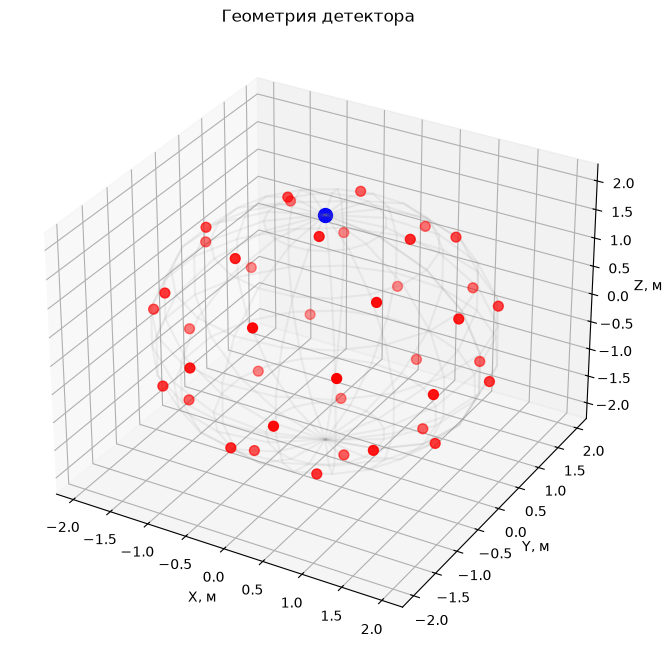

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

class Detector:
    def __init__(self, R=2.0, N=40, r=0.1, a=0.5):
        self.R = R
        self.N = N
        self.r = r
        self.a = a
        
        indices = np.arange(0, N, dtype=float) + 0.5
        phi = np.arccos(1 - 2 * indices / N)
        theta = np.pi * (1 + 5**0.5) * indices
        
        x = np.cos(theta) * np.sin(phi) * R
        y = np.sin(theta) * np.sin(phi) * R
        z = np.cos(phi) * R
        
        self.pmt_positions = np.column_stack((x, y, z))

    def is_hit(self, point):
        distances = np.linalg.norm(self.pmt_positions - point, axis=1)
        return np.any(distances <= self.r)

# Проверка работы
det = Detector()
print(f"Создан детектор с {det.N} ФЭУ.")

# Визуализация
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
u, v = np.mgrid[0:2*np.pi:20j, 0:np.pi:10j]
x = det.R * np.cos(u) * np.sin(v)
y = det.R * np.sin(u) * np.sin(v)
z = det.R * np.cos(v)
ax.plot_wireframe(x, y, z, color="gray", alpha=0.1)
ax.scatter(det.pmt_positions[:,0], det.pmt_positions[:,1], det.pmt_positions[:,2], color='red', s=50, label='ФЭУ')
test_point = np.array([0, 0, det.R])
ax.scatter(*test_point, color='blue', s=100, label='Тестовая точка')
ax.set_xlabel('X, м')
ax.set_ylabel('Y, м')
ax.set_zlabel('Z, м')
plt.title("Геометрия детектора")
plt.show()

In [2]:
class Source:
    def __init__(self, Y=10000.0):
        self.Y = Y

    def generate_photons(self, E, position=(0, 0, 0)):
        N_photons = int(self.Y * E)
        cos_theta = np.random.uniform(-1, 1, N_photons)
        phi = np.random.uniform(0, 2 * np.pi, N_photons)
        sin_theta = np.sqrt(1 - cos_theta**2)
        
        nx = sin_theta * np.cos(phi)
        ny = sin_theta * np.sin(phi)
        nz = cos_theta
        
        directions = np.column_stack((nx, ny, nz))
        return np.array(position), directions

# Проверка
src = Source()
start_pos, dirs = src.generate_photons(E=1.0, position=(0, 0, 0))
print(f"Для E=1 МэВ сгенерировано {len(dirs)} фотонов.")

Для E=1 МэВ сгенерировано 10000 фотонов.


In [3]:
def find_hit_pmt(detector, start_pos, directions):
    R = detector.R
    b = 2 * np.sum(start_pos * directions, axis=1)
    c = np.sum(start_pos**2) - R**2
    discriminant = b**2 - 4 * c
    
    t = (-b + np.sqrt(discriminant)) / 2
    hit_points = start_pos + t[:, np.newaxis] * directions
    
    hit_indices = np.full(len(hit_points), -1, dtype=int)
    for i, pt in enumerate(hit_points):
        distances = np.linalg.norm(detector.pmt_positions - pt, axis=1)
        if np.min(distances) <= detector.r:
            hit_indices[i] = np.argmin(distances)
            
    return hit_indices, hit_points

# Создаем класс-наследник
class DetectorWithPE(Detector):
    def get_photoelectrons(self, num_photons_hit):
        return np.random.poisson(self.a * num_photons_hit)

# Проверка
det = DetectorWithPE()
src = Source()
start_pos, dirs = src.generate_photons(E=1.0, position=(0, 0, 0))
hits, _ = find_hit_pmt(det, start_pos, dirs)
num_hits = np.sum(hits != -1)
print(f"Из {len(dirs)} фотонов в ФЭУ попало: {num_hits} ({num_hits/len(dirs)*100:.2f}%)")

total_pe = 0
for pmt_id in range(det.N):
    photons_in_this_pmt = np.sum(hits == pmt_id)
    pe = det.get_photoelectrons(photons_in_this_pmt)
    total_pe += pe

print(f"Полный собранный заряд для 1 события: {total_pe}")
Q_expected = det.a * src.Y * (det.N * np.pi * det.r**2) / (4 * np.pi * det.R**2)
print(f"Ожидаемый заряд (Q): {Q_expected:.1f}")

Из 10000 фотонов в ФЭУ попало: 249 (2.49%)
Полный собранный заряд для 1 события: 112
Ожидаемый заряд (Q): 125.0


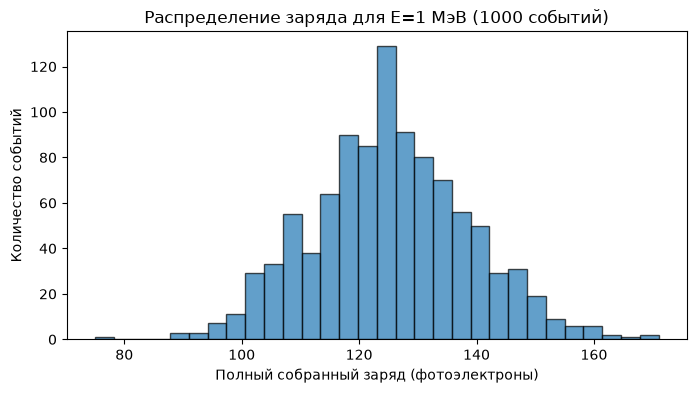

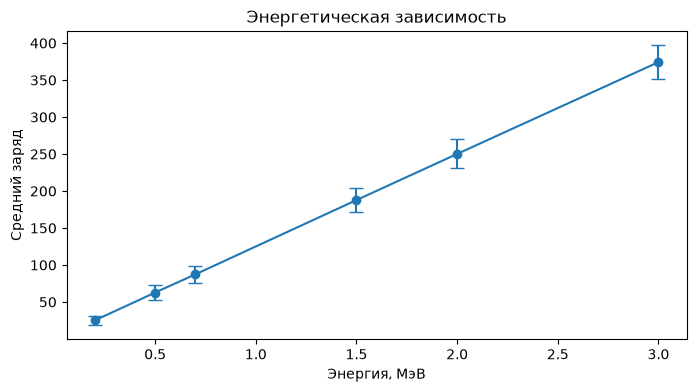

In [4]:
def simulate_event(detector, source, E, position=(0, 0, 0)):
    start_pos, dirs = source.generate_photons(E, position)
    hits, _ = find_hit_pmt(detector, start_pos, dirs)
    total_pe = 0
    for pmt_id in range(detector.N):
        photons_in_pmt = np.sum(hits == pmt_id)
        total_pe += detector.get_photoelectrons(photons_in_pmt)
    return total_pe

det = DetectorWithPE()
src = Source()
charges = [simulate_event(det, src, E=1.0) for _ in range(1000)]

plt.figure(figsize=(8, 4))
plt.hist(charges, bins=30, alpha=0.7, edgecolor='black')
plt.xlabel('Полный собранный заряд (фотоэлектроны)')
plt.ylabel('Количество событий')
plt.title('Распределение заряда для E=1 МэВ (1000 событий)')
plt.show()

# Графики для других энергий
energies = [0.2, 0.5, 0.7, 1.5, 2.0, 3.0]
means = []
stds = []
for E in energies:
    event_charges = [simulate_event(det, src, E) for _ in range(1000)]
    means.append(np.mean(event_charges))
    stds.append(np.std(event_charges))

plt.figure(figsize=(8, 4))
plt.errorbar(energies, means, yerr=stds, fmt='o-', capsize=5)
plt.xlabel('Энергия, МэВ')
plt.ylabel('Средний заряд')
plt.title('Энергетическая зависимость')
plt.show()